# 01 · Data Exploration

**Goal:** understand the data before building a model.

- **Input:** `data/raw/train.csv` (221 fires with answers)
- **Output:** 3 charts in `reports/figures/`, and `data/processed/train_clean.csv`

**Question:** what is the chance (%) that a fire gets within 5 km of an evacuation zone within 12, 24, 48 or 72 hours?

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

from src.data import load_raw, clean, make_labels, feature_columns, HORIZONS, TIME_COL, EVENT_COL
from src.features import add_features

## 1. Load and check the data

In [2]:
train, test = load_raw(DATA_DIR / "raw")
train = clean(train)
FEATURES = feature_columns(train)

print("Train:", train.shape, "| Test:", test.shape)
print("Missing values:", train.isna().sum().sum(), "| Duplicate fires:", train["event_id"].duplicated().sum())
train.head()

Train: (221, 37) | Test: (95, 35)
Missing values: 0 | Duplicate fires: 0


,event_id,num_perimeters_0_5h,dt_first_last_0_5h,low_temporal_resolution_0_5h,area_first_ha,area_growth_abs_0_5h,area_growth_rel_0_5h,area_growth_rate_ha_per_h,log1p_area_first,log1p_growth,...,dist_fit_r2_0_5h,alignment_cos,alignment_abs,cross_track_component,along_track_speed,event_start_hour,event_start_dayofweek,event_start_month,time_to_hit_hours,event
0,10892457,3,4.265188,0,79.696304,2.875935,0.036086,0.674281,4.390693,1.354787,...,0.886373,-0.054649,0.054649,-1.937219,-0.106026,19,4,5,18.892512,0
1,11757157,2,1.169918,0,8.946749,0.000000,0.000000,0.000000,2.297246,0.000000,...,0.000000,-0.568898,0.568898,-0.000000,-0.000000,4,4,6,22.048108,1
2,11945086,4,4.777526,0,106.482638,0.000000,0.000000,0.000000,4.677329,0.000000,...,0.000000,0.882385,0.882385,0.000000,0.000000,22,4,8,0.888895,1
3,12044083,1,0.000000,1,67.631125,0.000000,0.000000,0.000000,4.228746,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,20,5,8,60.953021,0
4,12052347,2,4.975273,0,35.632874,0.000000,0.000000,0.000000,3.600946,0.000000,...,0.000000,0.934634,0.934634,-0.000000,0.000000,21,5,7,44.990274,0


Clean data: 34 numeric features, no missing values, no duplicates.

## 2. The target
- `event`: 1 = the fire reached the zone, 0 = it didn't (as far as we know)
- `time_to_hit_hours`: when it reached it, or when we stopped watching it

**Competition rule:** if we stopped watching a fire *before* a time limit, we don't know what happened, so we **skip** that fire for that limit.

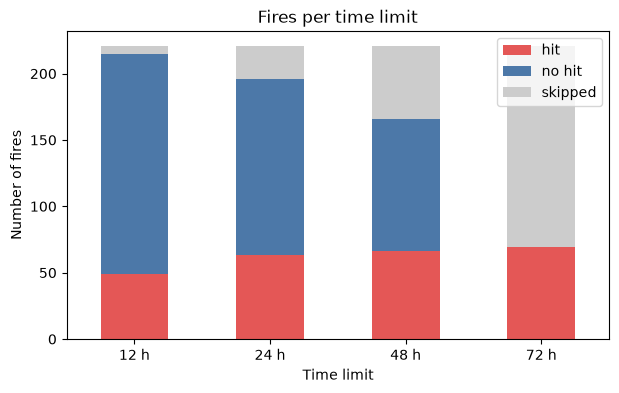

,hit,no hit,skipped
12 h,49,166,6
24 h,63,133,25
48 h,66,100,55
72 h,69,0,152


In [3]:
labels = make_labels(train[TIME_COL], train[EVENT_COL])
counts = pd.DataFrame({"hit": (labels == 1).sum(), "no hit": (labels == 0).sum(), "skipped": labels.isna().sum()})
counts.index = [f"{h} h" for h in HORIZONS]

counts.plot.bar(stacked=True, color=["#E45756", "#4C78A8", "#CCCCCC"], figsize=(7, 4), rot=0)
plt.title("Fires per time limit")
plt.xlabel("Time limit"); plt.ylabel("Number of fires")
plt.savefig(FIG_DIR / "01_target.png", bbox_inches="tight"); plt.show()
counts

Only **31%** of fires reach the zone, and most do it **fast**. At 72 h every fire we can judge is a hit, because we stopped watching all the others before 72 h.

## 3. Distance decides almost everything

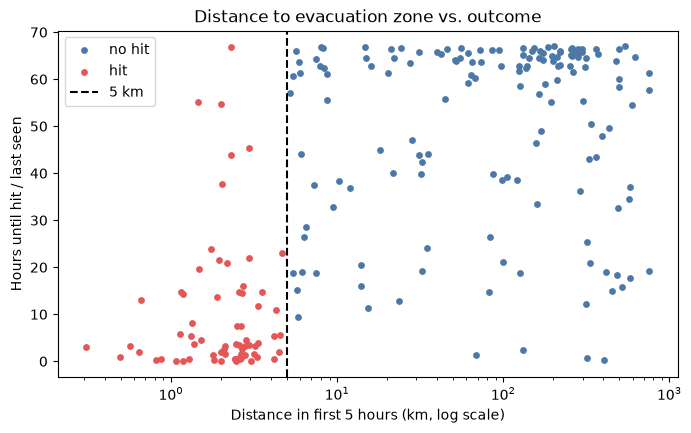

Farthest fire that hit: 4.7 km
Closest fire that did not hit: 5.2 km


In [4]:
hit = train[EVENT_COL] == 1
plt.figure(figsize=(8, 4.5))
plt.scatter(train.loc[~hit, "dist_min_ci_0_5h"] / 1000, train.loc[~hit, TIME_COL], color="#4C78A8", s=15, label="no hit")
plt.scatter(train.loc[hit, "dist_min_ci_0_5h"] / 1000, train.loc[hit, TIME_COL], color="#E45756", s=15, label="hit")
plt.axvline(5, color="black", linestyle="--", label="5 km")
plt.xscale("log")
plt.title("Distance to evacuation zone vs. outcome")
plt.xlabel("Distance in first 5 hours (km, log scale)"); plt.ylabel("Hours until hit / last seen")
plt.legend(); plt.savefig(FIG_DIR / "01_distance.png", bbox_inches="tight"); plt.show()

print("Farthest fire that hit: %.1f km" % (train.loc[hit, "dist_min_ci_0_5h"].max() / 1000))
print("Closest fire that did not hit: %.1f km" % (train.loc[~hit, "dist_min_ci_0_5h"].min() / 1000))

⚠️ **Key finding:** every fire that hit started **within 4.7 km** of the zone, and every fire that didn't was **more than 5.2 km** away.
So *whether* a fire hits is easy to predict. The hard part is *when*.

## 4. Which features are most linked to a hit?

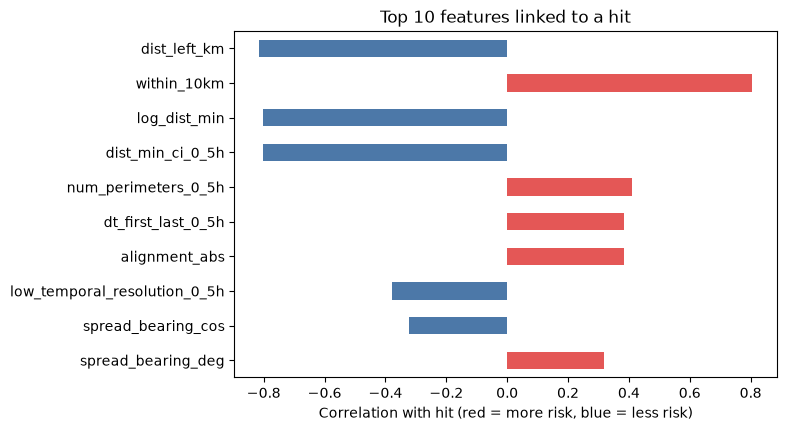

In [5]:
X = add_features(train[FEATURES])
corr = X.corrwith(train[EVENT_COL], method="spearman").dropna()
top = corr.reindex(corr.abs().sort_values().index).tail(10)

top.plot.barh(color=["#E45756" if v > 0 else "#4C78A8" for v in top], figsize=(7, 4.5))
plt.title("Top 10 features linked to a hit")
plt.xlabel("Correlation with hit (red = more risk, blue = less risk)"); plt.ylabel("")
plt.savefig(FIG_DIR / "01_top_features.png", bbox_inches="tight"); plt.show()

Distance features are at the top. Fires that were mapped more often and moved toward the zone are also riskier.

In [6]:
(DATA_DIR / "processed").mkdir(exist_ok=True)
train.to_csv(DATA_DIR / "processed" / "train_clean.csv", index=False)

## Key Findings
1. **Small data:** only 221 fires, so we use cross-validation to compare models.
2. **Distance is the main signal:** fires within about 5 km hit. *When* they hit is the real challenge.
3. **Skipped rows:** fires we stopped watching early are left out at later time limits (competition rule).
4. **Many features are 0:** most fires were mapped only once in the first 5 hours. Tree models handle this well.